In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from pathlib import Path

DATA_DIR = Path("dataverse_files")

print(Path.cwd())
print((DATA_DIR / "attenders-network-stats.csv").resolve())

# Load comparable datasets
protesters = pd.read_csv(
    DATA_DIR / "attenders-network-stats.csv",
    index_col=0
)

paris = pd.read_csv(
    DATA_DIR / "paris-control-network-stats-excl-verified.csv",
    index_col=0
)

france = pd.read_csv(
    DATA_DIR / "france-control-network-stats.csv",
    index_col=0
)

# Preview
print("Protesters:", protesters.shape)
print("Paris:", paris.shape)
print("France:", france.shape)

print(protesters.head())


/Users/kellylao/Desktop/AIT Budapest/Networks/protestsimulation
/Users/kellylao/Desktop/AIT Budapest/Networks/protestsimulation/dataverse_files/attenders-network-stats.csv
Protesters: (764, 35)
Paris: (752, 35)
France: (764, 35)
           num_friends  num_friends_in_users_set  \
83518016            88                         0   
13155964           428                         2   
47307730          1314                         8   
108589651          691                         4   
13500799           682                        20   

           proportion_friends_in_users_set  num_friends_in_protesters_set  \
83518016                          0.000000                              0   
13155964                          0.004673                              2   
47307730                          0.006088                              8   
108589651                         0.005789                              4   
13500799                          0.029326                             20

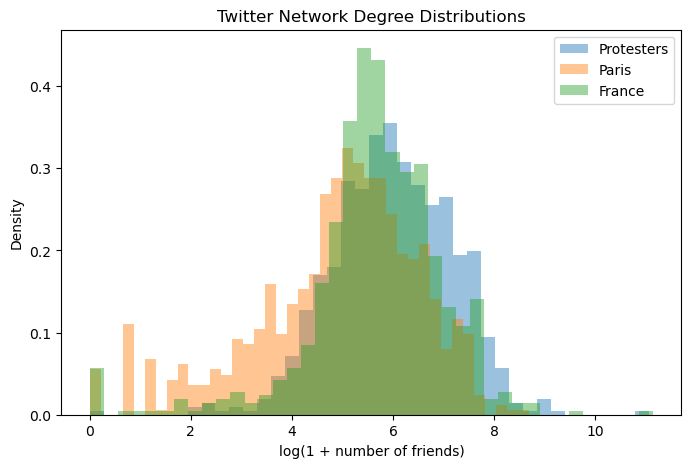

In [2]:
groups = {
    "Protesters": protesters,
    "Paris": paris,
    "France": france
}

metric = "num_friends"

plt.figure(figsize=(8, 5))

for name, df in groups.items():
    values = df[metric].dropna()
    plt.hist(
        np.log1p(values),
        bins=40,
        alpha=0.45,
        density=True,
        label=name
    )

plt.xlabel("log(1 + number of friends)")
plt.ylabel("Density")
plt.title("Twitter Network Degree Distributions")
plt.legend()
plt.show()


In [ ]:
# Network parameters
N = 300
COMMUNITY_SIZE = 100
NUM_COMMUNITIES = 3

P_IN = 0.10
P_OUT = 0.01

SEED = 42
rng = np.random.default_rng(SEED)

sizes = [COMMUNITY_SIZE] * NUM_COMMUNITIES

# Probability of connecting communities
probs = [
    [P_IN if i == j else P_OUT
     for j in range(NUM_COMMUNITIES)]
    for i in range(NUM_COMMUNITIES)
]

G = nx.stochastic_block_model(
    sizes,
    probs,
    seed=SEED
)

# Map each node to its community
communities = {
    node: community
    for community, nodes in enumerate(G.graph["partition"])
    for node in nodes
}

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Average degree:", 2 * G.number_of_edges() / N)
print("Clustering:", nx.average_clustering(G))


Nodes: 300
Edges: 1739
Average degree: 11.593333333333334
Clustering: 0.06875197575042775


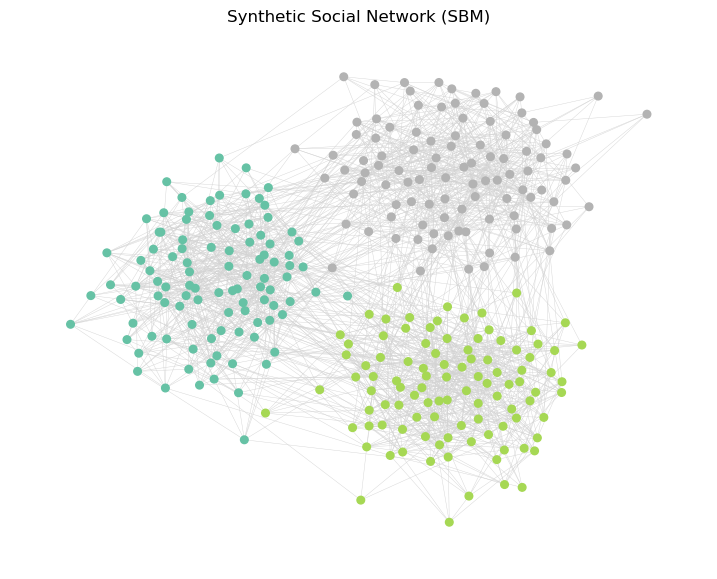

In [4]:
pos = nx.spring_layout(G, seed=SEED)

colors = [
    communities[node]
    for node in G.nodes()
]

plt.figure(figsize=(9, 7))

nx.draw_networkx(
    G,
    pos=pos,
    node_color=colors,
    cmap=plt.cm.Set2,
    node_size=30,
    edge_color="lightgray",
    width=0.3,
    with_labels=False
)

plt.title("Synthetic Social Network (SBM)")
plt.axis("off")
plt.show()


In [5]:
def simulate_protest(
    G,
    thresholds,
    initial_active,
    max_steps=100
):
    active = set(initial_active)
    history = [len(active) / G.number_of_nodes()]

    for t in range(max_steps):
        new_active = set(active)

        for node in G.nodes():
            if node in active:
                continue

            neighbors = list(G.neighbors(node))

            if len(neighbors) == 0:
                continue

            active_neighbors = sum(
                neighbor in active
                for neighbor in neighbors
            )

            fraction_active = (
                active_neighbors / len(neighbors)
            )

            if fraction_active >= thresholds[node]:
                new_active.add(node)

        # All nodes update synchronously
        if new_active == active:
            break

        active = new_active
        history.append(len(active) / G.number_of_nodes())

    return active, history


In [6]:
# Assign participation thresholds
thresholds = {
    node: rng.uniform(0.10, 0.30)
    for node in G.nodes()
}

# Initial protesters come from community 0
community_0 = list(G.graph["partition"][0])

initial_active = rng.choice(
    community_0,
    size=10,
    replace=False
)

# Run simulation
final_active, history = simulate_protest(
    G,
    thresholds,
    initial_active
)

print("Final active nodes:", len(final_active))
print("Final participation:", round(history[-1], 3))
print("Large-scale cascade:", history[-1] >= 0.50)


Final active nodes: 300
Final participation: 1.0
Large-scale cascade: True


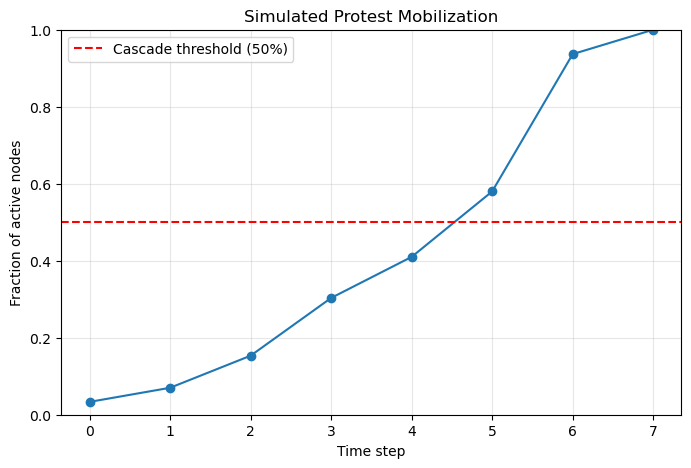

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(len(history)),
    history,
    marker="o"
)

plt.axhline(
    y=0.5,
    color="red",
    linestyle="--",
    label="Cascade threshold (50%)"
)

plt.xlabel("Time step")
plt.ylabel("Fraction of active nodes")
plt.title("Simulated Protest Mobilization")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [8]:
def run_experiments(
    n_simulations=20,
    p_out=0.01
):
    results = []

    for seed in range(n_simulations):
        rng = np.random.default_rng(seed)

        probs = [
            [P_IN if i == j else p_out
             for j in range(NUM_COMMUNITIES)]
            for i in range(NUM_COMMUNITIES)
        ]

        G = nx.stochastic_block_model(
            sizes,
            probs,
            seed=seed
        )

        thresholds = {
            node: rng.uniform(0.10, 0.30)
            for node in G.nodes()
        }

        community_0 = list(G.graph["partition"][0])

        initial_active = rng.choice(
            community_0,
            size=10,
            replace=False
        )

        final_active, history = simulate_protest(
            G,
            thresholds,
            initial_active
        )

        reached = np.flatnonzero(
            np.array(history) >= 0.5
        )

        results.append({
            "seed": seed,
            "p_out": p_out,
            "final_fraction": history[-1],
            "cascade": int(history[-1] >= 0.5),
            "time_to_cascade": (
                int(reached[0])
                if len(reached) > 0
                else np.nan
            ),
            "max_growth": max(
                np.diff(history),
                default=0
            )
        })

    return pd.DataFrame(results)


# Run experiments for different bridge densities
results = pd.concat([
    run_experiments(p_out=p)
    for p in [0.01, 0.03, 0.05]
], ignore_index=True)

print(
    results.groupby("p_out")[
        ["cascade", "final_fraction", "time_to_cascade"]
    ].mean()
)


       cascade  final_fraction  time_to_cascade
p_out                                          
0.01      1.00          1.0000         5.100000
0.03      0.95          0.9530         6.000000
0.05      0.45          0.4765         8.222222


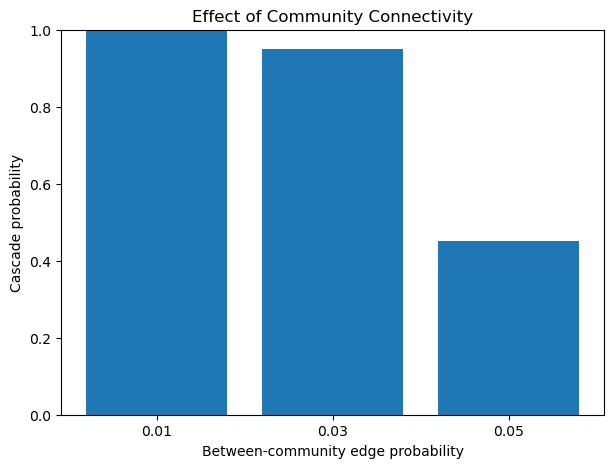

In [9]:
cascade_rates = results.groupby("p_out")["cascade"].mean()

plt.figure(figsize=(7, 5))
plt.bar(
    cascade_rates.index.astype(str),
    cascade_rates.values
)

plt.xlabel("Between-community edge probability")
plt.ylabel("Cascade probability")
plt.title("Effect of Community Connectivity")
plt.ylim(0, 1)
plt.show()
